In [ ]:
!python imageconverter.py

In [13]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, top_k_accuracy_score
from transformers import color_histogram
from pathlib import Path
import matplotlib.pyplot as plt


In [14]:
train_df = pd.read_csv("train_set.csv")
test_df = pd.read_csv("test_set.csv")

In [15]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96079 entries, 0 to 96078
Columns: 147 entries, country_code to edge_density_bottom
dtypes: bool(1), float64(134), int64(5), str(7)
memory usage: 118.6 MB


In [16]:

feature_cols = [c for c in train_df.columns if c not in ["country", "image_name"]]



missing = train_df[feature_cols].isnull().sum()
missing_pct = (missing / len(train_df) * 100).round(2)
missing_df = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
missing_df = missing_df[missing_df["Missing Count"] > 0].sort_values("Missing %", ascending=False)
print(missing_df.to_string())

                    Missing Count  Missing %
country_code                  897       0.93
coord_country_code            888       0.92


In [17]:
print(train_df.index.is_unique, train_df.index.max(), len(train_df))
print(test_df.index.is_unique, test_df.index.max(), len(test_df))

True 96078 96079
True 10675 10676


In [18]:
missing_cc = train_df[train_df['country_code'].isna()]
print(missing_cc.groupby('country').size().sort_values(ascending=False))

country
Namibia         877
Botswana         14
South Africa      6
dtype: int64


Missing values are because of Namibia " NA ". Thats fine well drop all but country they all the same. 

In [19]:

feature_cols = [c for c in train_df.columns if c not in ["country", "image_name"]]



missing = train_df[feature_cols].isnull().sum()
missing_pct = (missing / len(train_df) * 100).round(2)
missing_df = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
missing_df = missing_df[missing_df["Missing Count"] > 0].sort_values("Missing %", ascending=False)
print(missing_df.to_string())

                    Missing Count  Missing %
country_code                  897       0.93
coord_country_code            888       0.92


In [20]:
train_df.keys()

Index(['country_code', 'image_name', 'width', 'height', 'size', 'path',
       'latitude', 'longitude', 'heading', 'country',
       ...
       'lbp_39', 'ground_hue_mean', 'ground_sat_mean', 'ground_val_mean',
       'ground_grey_frac', 'brightness_mean', 'contrast_std',
       'edge_density_total', 'edge_density_top', 'edge_density_bottom'],
      dtype='str', length=147)

In [21]:
numeric_cols = train_df.select_dtypes(include=[np.number]).columns
corr_matrix = train_df[numeric_cols].corr()

corr_pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack()
high_corr = corr_pairs[corr_pairs.abs() > 0.8].sort_values(ascending=False)

print(high_corr)

size                edge_density_total     0.966164
lbp_0               lbp_9                  0.958615
lbp_10              lbp_19                 0.955514
lbp_1               lbp_9                  0.955226
vari_mean           vari_std               0.953062
lbp_11              lbp_19                 0.951424
lbp_30              lbp_39                 0.932188
lbp_20              lbp_29                 0.932166
lbp_0               lbp_1                  0.922506
lbp_10              lbp_11                 0.920591
hsv_bin_29          hsv_bin_30             0.906666
size                edge_density_top       0.894092
edge_density_total  edge_density_top       0.891680
lbp_31              lbp_39                 0.873769
lbp_21              lbp_29                 0.870919
hsv_bin_28          hsv_bin_29             0.865025
lbp_20              lbp_21                 0.844294
lbp_30              lbp_31                 0.840320
hsv_bin_30          hsv_bin_31             0.836538
hsv_bin_34  

In [22]:
DATA_PATH = Path("data/images/streetview_images")

if not any(DATA_PATH.iterdir()):
    path = kagglehub.dataset_download(
        "sylshaw/streetview-by-country",
        output_dir=str(DATA_PATH)
    )
else:
    path = str(DATA_PATH)

print("Path to dataset:", path)

Path to dataset: data/images/streetview_images


In [23]:
old_hsv_cols = [c for c in train_df.columns if c.startswith('hsv_bin_')]
train_df = train_df.drop(columns=old_hsv_cols)
test_df = test_df.drop(columns=old_hsv_cols)

train_features = [color_histogram(path) for path in train_df['path']]
test_features = [color_histogram(path) for path in test_df['path']]

train_hsv_cols = pd.DataFrame(train_features, columns=[f'hsv_bin_{i}' for i in range(48)])
test_hsv_cols = pd.DataFrame(test_features, columns=[f'hsv_bin_{i}' for i in range(48)])

train_df = pd.concat([train_df.reset_index(drop=True), train_hsv_cols], axis=1)
test_df = pd.concat([test_df.reset_index(drop=True), test_hsv_cols], axis=1)

In [24]:
from sklearn.decomposition import PCA

def fit_full_pca(df):
    lbp_cols = [c for c in df.columns if c.startswith('lbp')]
    pca = PCA()
    pca.fit(df[lbp_cols])
    return pca

In [25]:

pca = fit_full_pca(train_df)

In [26]:
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)
print("Cumulative Variance:")
print(cumulative_variance)
print(f"Components for 80% variance: {np.argmax(cumulative_variance >= 0.80) + 1}")


Cumulative Variance:
[0.36931468 0.59649358 0.71509513 0.79284805 0.85406926 0.89512261
 0.93000495 0.94400384 0.95587638 0.96481216 0.96988139 0.97435668
 0.97786711 0.9802181  0.98246554 0.98445001 0.98576217 0.98702394
 0.9881589  0.9892409  0.99026265 0.9911956  0.99207872 0.99292138
 0.99368065 0.99440114 0.99511061 0.99577117 0.99642418 0.99704158
 0.99760882 0.99815381 0.99864783 0.99911758 0.99958382 1.
 1.         1.         1.         1.        ]
Components for 80% variance: 5


In [27]:

n_pca_components = 7

def apply_pca_to_lbp(df, n_components):
    lbp_cols = [c for c in df.columns if c.startswith('lbp')]
    pca = PCA(n_components=n_components)
    lbp_pca = pca.fit_transform(df[lbp_cols])
    lbp_pca_cols = pd.DataFrame(lbp_pca, columns=[f'lbp_pca_{i}' for i in range(lbp_pca.shape[1])])
    df = pd.concat([df.drop(columns=lbp_cols).reset_index(drop=True), lbp_pca_cols], axis=1)
    return df, pca

def transform_pca_lbp(df, pca):
    lbp_cols = [c for c in df.columns if c.startswith('lbp')]
    lbp_pca = pca.transform(df[lbp_cols])
    lbp_pca_cols = pd.DataFrame(lbp_pca, columns=[f'lbp_pca_{i}' for i in range(lbp_pca.shape[1])])
    df = pd.concat([df.drop(columns=lbp_cols).reset_index(drop=True), lbp_pca_cols], axis=1)
    return df


In [28]:
train_df, pca = apply_pca_to_lbp(train_df, n_pca_components)
test_df = transform_pca_lbp(test_df, pca)

In [29]:
numeric_cols = train_df.select_dtypes(include=[np.number]).columns
corr_matrix = train_df[numeric_cols].corr()

corr_pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack()
high_corr = corr_pairs[corr_pairs.abs() > 0.8].sort_values(ascending=False)

print(high_corr)

size                edge_density_total     0.966164
vari_mean           vari_std               0.953062
hsv_bin_29          hsv_bin_30             0.906666
size                edge_density_top       0.894092
edge_density_total  edge_density_top       0.891680
hsv_bin_28          hsv_bin_29             0.865025
hsv_bin_30          hsv_bin_31             0.836538
hsv_bin_34          hsv_bin_35             0.835752
hsv_bin_33          hsv_bin_34             0.827221
edge_density_total  edge_density_bottom    0.802613
dtype: float64


In [30]:
from sklearn.feature_selection import f_classif


feature_cols = [c for c in numeric_cols if c not in ['latitude', 'longitude', 'heading']]
f_scores, p_values = f_classif(train_df[feature_cols], train_df['country'])

feature_importance = pd.Series(f_scores, index=feature_cols).sort_values(ascending=False)
print(feature_importance)

sky_fraction    655.269559
lbp_pca_2       484.828946
size            438.704084
hog_pca_0       436.532367
contrast_std    363.839147
                   ...    
lbp_pca_3         1.904695
lbp_pca_4         1.834298
width                  NaN
height                 NaN
channels               NaN
Length: 103, dtype: float64


/home/pedrosalgado22/.local/lib/python3.14/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [0 1 3] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/pedrosalgado22/.local/lib/python3.14/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


In [31]:
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(train_df[feature_cols], train_df['country'], random_state=42)
mi_importance = pd.Series(mi_scores, index=feature_cols).sort_values(ascending=False)
print(mi_importance)

sky_fraction    0.370436
hsv_bin_47      0.309377
hsv_bin_31      0.299402
vari_mean       0.290499
hsv_bin_46      0.290084
                  ...   
lbp_pca_3       0.024259
lbp_pca_4       0.021573
width           0.001093
height          0.000000
channels        0.000000
Length: 103, dtype: float64


In [32]:
drop_cols = ['country_code', 'width', 'height', 'size', 'path', 'coord_country_code',
             'corrupted', 'channels', 'phash', 'latitude', 'vari_std', 'longitude', 'hsv_bin_34', 'hsv_bin_29', 'edge_density_total', 'continent']

train_df = train_df.drop(columns=drop_cols)
test_df = test_df.drop(columns=drop_cols)

In [33]:
f_scores_series = pd.Series(f_scores, index=feature_cols)

In [34]:
mi_threshold = mi_importance.quantile(0.2)
f_threshold = feature_importance.quantile(0.2)

drop_cols2 = [c for c in feature_cols if mi_importance[c] <= mi_threshold and f_scores_series[c] <= f_threshold]

In [35]:
train_df = train_df.drop(columns=drop_cols2)
test_df = test_df.drop(columns=drop_cols2)

In [36]:
feature_cols = [c for c in train_df.columns if c not in ["country", "image_name"]]


In [37]:
skewness = train_df[feature_cols].skew().sort_values(ascending=False)

skewed_features = skewness[(skewness > 2) | (skewness < -2)]
skewed_df = pd.DataFrame({'feature': skewed_features.index, 'skewness': skewed_features.values})
print(skewed_df)

       feature   skewness
0   hsv_bin_32  34.094460
1   hsv_bin_14   7.066895
2    vari_mean   6.949759
3   hsv_bin_30   6.792065
4   hsv_bin_28   6.784120
5   hsv_bin_13   6.439854
6   hsv_bin_27   5.190380
7   hsv_bin_15   5.092590
8   hsv_bin_12   4.709504
9   hsv_bin_11   4.433482
10  hsv_bin_33   4.206103
11  hsv_bin_26   4.026585
12  hsv_bin_31   3.725032
13   hsv_bin_5   3.327745
14   hsv_bin_6   3.087945
15  hsv_bin_25   2.989727
16   hsv_bin_7   2.944304
17  hsv_bin_10   2.807677
18   hsv_bin_4   2.493907
19  hsv_bin_24   2.396733
20  hsv_bin_35   2.259421
21  hsv_bin_23   2.063125
22   hsv_bin_0   2.024697
23   lbp_pca_2  -2.436208


In [38]:
print((train_df[skewed_df['feature']] < 0).sum())

hsv_bin_32        0
hsv_bin_14        0
vari_mean     14008
hsv_bin_30        0
hsv_bin_28        0
hsv_bin_13        0
hsv_bin_27        0
hsv_bin_15        0
hsv_bin_12        0
hsv_bin_11        0
hsv_bin_33        0
hsv_bin_26        0
hsv_bin_31        0
hsv_bin_5         0
hsv_bin_6         0
hsv_bin_25        0
hsv_bin_7         0
hsv_bin_10        0
hsv_bin_4         0
hsv_bin_24        0
hsv_bin_35        0
hsv_bin_23        0
hsv_bin_0         0
lbp_pca_2     32667
dtype: int64


In [39]:
neg_cols = ['vari_mean', 'lbp_pca_2']
log_cols = [c for c in skewed_df['feature'] if c not in neg_cols]

for col in log_cols:
    train_df[col] = np.log1p(train_df[col])
    test_df[col] = np.log1p(test_df[col])

for col in ['vari_mean']:
    train_df[col] = np.sign(train_df[col]) * np.log1p(np.abs(train_df[col]))
    test_df[col] = np.sign(test_df[col]) * np.log1p(np.abs(test_df[col]))

In [40]:
def winsorize_continuous_train_test(df_train, df_test, lower_pct=0.01, upper_pct=0.99):
    df_train = df_train.copy()
    df_test = df_test.copy()
    continuous_cols = [c for c in df_train.columns if c not in ["country", "image_name"]]

    for col in continuous_cols:
        if col in df_train.columns:
            lo = df_train[col].quantile(lower_pct)
            hi = df_train[col].quantile(upper_pct)
            n_outliers_train = ((df_train[col] < lo) | (df_train[col] > hi)).sum()
            df_train[col] = df_train[col].clip(lo, hi)
            df_test[col] = df_test[col].clip(lo, hi)

    return df_train, df_test

In [41]:
train_df, test_df = winsorize_continuous_train_test(train_df, test_df)

In [42]:
from sklearn.preprocessing import StandardScaler

feature_cols = [c for c in train_df.columns if c not in ["country", "image_name"]]


scaler = StandardScaler()
train_df[feature_cols] = scaler.fit_transform(train_df[feature_cols])
test_df[feature_cols] = scaler.transform(test_df[feature_cols])

In [43]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96079 entries, 0 to 96078
Data columns (total 82 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   image_name           96079 non-null  str    
 1   heading              96079 non-null  float64
 2   country              96079 non-null  str    
 3   vari_mean            96079 non-null  float64
 4   vari_frac            96079 non-null  float64
 5   sky_fraction         96079 non-null  float64
 6   sky_blue_ratio       96079 non-null  float64
 7   hog_pca_0            96079 non-null  float64
 8   hog_pca_1            96079 non-null  float64
 9   hog_pca_2            96079 non-null  float64
 10  hog_pca_3            96079 non-null  float64
 11  hog_pca_5            96079 non-null  float64
 12  hog_pca_7            96079 non-null  float64
 13  hog_pca_8            96079 non-null  float64
 14  hog_pca_11           96079 non-null  float64
 15  hog_pca_13           96079 non-null  float64
 1

In [44]:
from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.10, random_state=42)
train_idx, val_idx = next(splitter.split(train_df, train_df["country"]))

train_split = train_df.iloc[train_idx]
val_split = train_df.iloc[val_idx]

In [45]:
train_names = train_split["image_name"].copy()
val_names = val_split["image_name"].copy()
test_names = test_df["image_name"].copy()

y_train = train_split["country"].copy()
y_val = val_split["country"].copy()
y_test = test_df["country"].copy()

X_train_raw = train_split.drop(columns=["image_name", "country"]).copy()
X_val_raw = val_split.drop(columns=["image_name", "country"]).copy()
X_test_raw = test_df.drop(columns=["image_name", "country"]).copy()

print(f"training features shape: {X_train_raw.shape}")
print(f"validation features shape: {X_val_raw.shape}")
print(f"test features shape: {X_test_raw.shape}")

training features shape: (86471, 80)
validation features shape: (9608, 80)
test features shape: (10676, 80)


In [46]:

lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_raw, y_train)

val_probs = lr_model.predict_proba(X_val_raw)
val_pred = lr_model.predict(X_val_raw)

print("Accuracy:", accuracy_score(y_val, val_pred))
print("Top-3 Accuracy:", top_k_accuracy_score(y_val, val_probs, k=3, labels=lr_model.classes_))

top3_idx = np.argsort(val_probs, axis=1)[:, ::-1][:, :3]
top3_countries = lr_model.classes_[top3_idx]

results = pd.DataFrame({
    "true_country": y_val.values,
    "guess_1": top3_countries[:, 0],
    "guess_2": top3_countries[:, 1],
    "guess_3": top3_countries[:, 2],
})

results.head()

Accuracy: 0.31817235636969193
Top-3 Accuracy: 0.49833472106577853


/home/pedrosalgado22/.local/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,true_country,guess_1,guess_2,guess_3
0,Albania,Albania,North Macedonia,Montenegro
1,Türkiye,Malaysia,Viet Nam,Romania
2,Northern Mariana Islands,Northern Mariana Islands,Guam,Bermuda
3,American Samoa,Malta,Dominican Republic,Lebanon
4,Japan,"Taiwan, Province of China",Slovenia,Hong Kong


In [47]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_raw, y_train)

val_probs = dt_model.predict_proba(X_val_raw)
val_pred = dt_model.predict(X_val_raw)

print("Accuracy:", accuracy_score(y_val, val_pred))
print("Top-3 Accuracy:", top_k_accuracy_score(y_val, val_probs, k=3, labels=dt_model.classes_))

top3_idx = np.argsort(val_probs, axis=1)[:, ::-1][:, :3]
top3_countries = dt_model.classes_[top3_idx]

results_dt = pd.DataFrame({
    "true_country": y_val.values,
    "guess_1": top3_countries[:, 0],
    "guess_2": top3_countries[:, 1],
    "guess_3": top3_countries[:, 2],
})

results_dt.head()

Accuracy: 0.15008326394671107
Top-3 Accuracy: 0.16371773522064945


,true_country,guess_1,guess_2,guess_3
0,Albania,Albania,"Virgin Islands, U.S.",Viet Nam
1,Türkiye,Poland,"Virgin Islands, U.S.",Viet Nam
2,Northern Mariana Islands,Northern Mariana Islands,"Virgin Islands, U.S.",Viet Nam
3,American Samoa,Curaçao,"Virgin Islands, U.S.",Viet Nam
4,Japan,"Taiwan, Province of China",Åland Islands,"Virgin Islands, U.S."


In [48]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=50, max_depth=15, n_jobs=-1, random_state=42)
rf_model.fit(X_train_raw, y_train)

val_probs = rf_model.predict_proba(X_val_raw)
val_pred = rf_model.predict(X_val_raw)

print("Accuracy:", accuracy_score(y_val, val_pred))
print("Top-3 Accuracy:", top_k_accuracy_score(y_val, val_probs, k=3, labels=rf_model.classes_))

top3_idx = np.argsort(val_probs, axis=1)[:, ::-1][:, :3]
top3_countries = rf_model.classes_[top3_idx]

results_rf = pd.DataFrame({
    "true_country": y_val.values,
    "guess_1": top3_countries[:, 0],
    "guess_2": top3_countries[:, 1],
    "guess_3": top3_countries[:, 2],
})

results_rf.head()

Accuracy: 0.2964196502914238
Top-3 Accuracy: 0.4555578684429642


,true_country,guess_1,guess_2,guess_3
0,Albania,Albania,North Macedonia,Ghana
1,Türkiye,Malaysia,Hong Kong,Singapore
2,Northern Mariana Islands,Northern Mariana Islands,Guam,North Macedonia
3,American Samoa,Greenland,American Samoa,"Korea, Republic of"
4,Japan,Bhutan,Slovenia,"Taiwan, Province of China"


In [49]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(X_train_raw, y_train)

val_probs = nb_model.predict_proba(X_val_raw)
val_pred = nb_model.predict(X_val_raw)

print("Accuracy:", accuracy_score(y_val, val_pred))
print("Top-3 Accuracy:", top_k_accuracy_score(y_val, val_probs, k=3, labels=nb_model.classes_))

top3_idx = np.argsort(val_probs, axis=1)[:, ::-1][:, :3]
top3_countries = nb_model.classes_[top3_idx]

results_nb = pd.DataFrame({
    "true_country": y_val.values,
    "guess_1": top3_countries[:, 0],
    "guess_2": top3_countries[:, 1],
    "guess_3": top3_countries[:, 2],
})

results_nb.head()

Accuracy: 0.1872398001665279
Top-3 Accuracy: 0.33701082431307244


,true_country,guess_1,guess_2,guess_3
0,Albania,Albania,Ghana,North Macedonia
1,Türkiye,Malaysia,Israel,Hong Kong
2,Northern Mariana Islands,Curaçao,Bermuda,Northern Mariana Islands
3,American Samoa,Gibraltar,Malta,Macao
4,Japan,Christmas Island,Bhutan,Slovenia


In [50]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV


lr_param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "penalty": ["l2"],
    "solver": ["saga"],
    "class_weight": ["balanced"]
}

lr_search = GridSearchCV(LogisticRegression(max_iter=1000, random_state=42), lr_param_grid, cv=2, scoring='accuracy', n_jobs=-1, verbose=3)
lr_search.fit(X_train_raw, y_train)

print(lr_search.best_params_)
print(lr_search.best_score_)

In [51]:
lr_param_grid = {
    "C": [1],
    "penalty": ["l2"],
    "solver": ["saga"],
    "class_weight": ["balanced"]
}

lr_search = GridSearchCV(LogisticRegression(max_iter=1000, random_state=42), lr_param_grid, cv=2, scoring='accuracy', n_jobs=-1, verbose=3)
lr_search.fit(X_train_raw, y_train)

print(lr_search.best_params_)
print(lr_search.best_score_)

Fitting 2 folds for each of 1 candidates, totalling 2 fits


/home/pedrosalgado22/.local/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/pedrosalgado22/.local/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


[CV 1/2] END C=1, class_weight=balanced, penalty=l2, solver=saga;, score=0.306 total time= 7.3min
[CV 2/2] END C=1, class_weight=balanced, penalty=l2, solver=saga;, score=0.308 total time= 7.5min


/home/pedrosalgado22/.local/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


{'C': 1, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'saga'}
0.30680807115161723



{'C': 1, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'saga'}
0.30680807115161723

rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 15, 25],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"],
    "class_weight": ["balanced"]
}

rf_search = RandomizedSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1), rf_param_grid, n_iter=15, cv=3, scoring='accuracy', random_state=42)
rf_search.fit(X_train_raw, y_train)

print(rf_search.best_params_)
print(rf_search.best_score_)

In [52]:
rf_param_grid = {
    "n_estimators": [200],
    "max_depth": [25],
    "min_samples_leaf": [1],
    "max_features": ["log2"],
    "class_weight": ["balanced"]
}

rf_search = RandomizedSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1), rf_param_grid, n_iter=15, cv=3, scoring='accuracy', random_state=42)
rf_search.fit(X_train_raw, y_train)

print(rf_search.best_params_)
print(rf_search.best_score_)

/home/pedrosalgado22/.local/lib/python3.14/site-packages/sklearn/model_selection/_search.py:324: UserWarning: The total space of parameters 1 is smaller than n_iter=15. Running 1 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


{'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 25, 'class_weight': 'balanced'}
0.32142567849947984


{'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 25, 'class_weight': 'balanced'}
0.32142567849947984

In [2]:
best_rf = rf_search.best_estimator_

test_probs_rf = best_rf.predict_proba(X_test_raw)
test_pred_rf = best_rf.predict(X_test_raw)

print("RF Test Top-1 Accuracy:", accuracy_score(y_test, test_pred_rf))
print("RF Test Top-2 Accuracy:", top_k_accuracy_score(y_test, test_probs_rf, k=2, labels=best_rf.classes_))
print("RF Test Top-3 Accuracy:", top_k_accuracy_score(y_test, test_probs_rf, k=3, labels=best_rf.classes_))

NameError: name 'rf_search' is not defined

In [54]:
best_lr = lr_search.best_estimator_

test_probs_lr = best_lr.predict_proba(X_test_raw)
test_pred_lr = best_lr.predict(X_test_raw)

print("LR Test Top-1 Accuracy:", accuracy_score(y_test, test_pred_lr))
print("LR Test Top-2 Accuracy:", top_k_accuracy_score(y_test, test_probs_lr, k=2, labels=best_lr.classes_))
print("LR Test Top-3 Accuracy:", top_k_accuracy_score(y_test, test_probs_lr, k=3, labels=best_lr.classes_))

LR Test Top-1 Accuracy: 0.31472461596103407
LR Test Top-2 Accuracy: 0.42778194080179843
LR Test Top-3 Accuracy: 0.494473585612589


In [55]:
print((best_rf.classes_ == best_lr.classes_).all())

True


In [56]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

calibrated_rf = CalibratedClassifierCV(FrozenEstimator(best_rf), method='isotonic')
calibrated_rf.fit(X_val_raw, y_val)

calibrated_lr = CalibratedClassifierCV(FrozenEstimator(best_lr), method='isotonic')
calibrated_lr.fit(X_val_raw, y_val)

test_probs_rf_cal = calibrated_rf.predict_proba(X_test_raw)
test_probs_lr_cal = calibrated_lr.predict_proba(X_test_raw)

ensemble_probs = (test_probs_rf_cal + test_probs_lr_cal) / 2

In [57]:
y_test_arr = np.asarray(y_test)

top3_idx = np.argsort(ensemble_probs, axis=1)[:, ::-1][:, :3]
top3_countries = calibrated_rf.classes_[top3_idx]

print("Calibrated Ensemble Top-1:", (y_test_arr == top3_countries[:, 0]).mean())
print("Calibrated Ensemble Top-2:", (y_test_arr[:, None] == top3_countries[:, :2]).any(axis=1).mean())
print("Calibrated Ensemble Top-3:", (y_test_arr[:, None] == top3_countries[:, :3]).any(axis=1).mean())

Calibrated Ensemble Top-1: 0.34582240539527914
Calibrated Ensemble Top-2: 0.45391532409142
Calibrated Ensemble Top-3: 0.5151742225552641


In [60]:
meta_X_val = np.hstack([best_rf.predict_proba(X_val_raw), best_lr.predict_proba(X_val_raw)])
meta_X_test = np.hstack([test_probs_rf, test_probs_lr])

meta_model = LogisticRegression(max_iter=2000)
meta_model.fit(meta_X_val, y_val)

stack_pred = meta_model.predict(meta_X_test)

In [61]:
meta_probs_test = meta_model.predict_proba(meta_X_test)
top3_idx = np.argsort(meta_probs_test, axis=1)[:, ::-1][:, :3]
top3_countries = meta_model.classes_[top3_idx]

y_test_arr = np.asarray(y_test)
print("Stacked Top-1:", (y_test_arr == top3_countries[:, 0]).mean())
print("Stacked Top-2:", (y_test_arr[:, None] == top3_countries[:, :2]).any(axis=1).mean())
print("Stacked Top-3:", (y_test_arr[:, None] == top3_countries[:, :3]).any(axis=1).mean())

Stacked Top-1: 0.3343949044585987
Stacked Top-2: 0.4385537654552267
Stacked Top-3: 0.505526414387411


In [62]:
importances = pd.Series(best_rf.feature_importances_, index=X_train_raw.columns).sort_values(ascending=False)
print(importances.to_string())

lbp_pca_2              0.018153
ground_hue_mean        0.015797
hsv_bin_1              0.015221
ground_grey_frac       0.015043
ground_sat_mean        0.014935
sky_fraction           0.014612
hsv_bin_2              0.014540
lbp_pca_5              0.014507
edge_density_bottom    0.014290
ground_val_mean        0.014258
hsv_bin_47             0.014236
hog_pca_3              0.014209
hsv_bin_10             0.013913
hsv_bin_0              0.013736
edge_density_top       0.013625
vari_mean              0.013569
lbp_pca_1              0.013541
hsv_bin_15             0.013384
brightness_mean        0.013376
hsv_bin_23             0.013291
lbp_pca_0              0.013227
hsv_bin_3              0.013212
hog_pca_0              0.013176
vari_frac              0.013077
hsv_bin_9              0.012914
hsv_bin_8              0.012876
hsv_bin_31             0.012817
hsv_bin_22             0.012809
hog_pca_7              0.012785
hsv_bin_11             0.012736
hsv_bin_32             0.012734
hsv_bin_

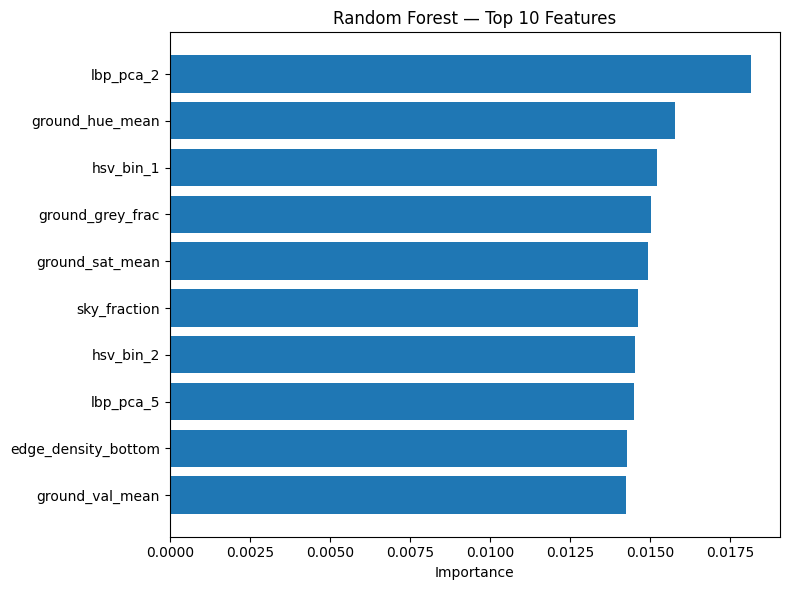

In [63]:
importances = pd.Series(best_rf.feature_importances_, index=X_train_raw.columns).sort_values(ascending=False)
top10 = importances.head(10)

plt.figure(figsize=(8, 6))
plt.barh(top10.index[::-1], top10.values[::-1])
plt.xlabel("Importance")
plt.title("Random Forest — Top 10 Features")
plt.tight_layout()
plt.show()

In [64]:
results_full = pd.DataFrame({
    "true_country": y_val.values,
    "guess_1": best_rf.classes_[np.argsort(val_probs, axis=1)[:, ::-1][:, 0]],
    "guess_2": best_rf.classes_[np.argsort(val_probs, axis=1)[:, ::-1][:, 1]],
    "guess_3": best_rf.classes_[np.argsort(val_probs, axis=1)[:, ::-1][:, 2]],
})

results_full["top1_correct"] = results_full["true_country"] == results_full["guess_1"]
results_full["top2_correct"] = results_full["top1_correct"] | (results_full["true_country"] == results_full["guess_2"])
results_full["top3_correct"] = results_full["top2_correct"] | (results_full["true_country"] == results_full["guess_3"])

country_stats = results_full.groupby("true_country")[["top1_correct", "top2_correct", "top3_correct"]].mean()
country_stats["n_images"] = results_full.groupby("true_country").size()
country_stats = country_stats.sort_values("top1_correct", ascending=False)

pd.set_option("display.max_rows", None)
print(country_stats)

                                  top1_correct  top2_correct  top3_correct  \
true_country                                                                 
Sao Tome and Principe                 0.773810      0.833333      0.833333   
Tunisia                               0.766667      0.788889      0.822222   
Oman                                  0.750000      0.880952      0.904762   
Macao                                 0.734940      0.819277      0.843373   
Isle of Man                           0.577778      0.655556      0.733333   
Namibia                               0.550562      0.741573      0.853933   
Singapore                             0.529412      0.568627      0.588235   
Christmas Island                      0.513889      0.611111      0.666667   
Eswatini                              0.511364      0.693182      0.727273   
Bhutan                                0.511111      0.655556      0.700000   
Qatar                                 0.511111      0.711111    

In [68]:
import pycountry
import pycountry_convert as pc

In [69]:
def to_continent(country):
    code = pycountry.countries.get(name=country).alpha_2
    return pc.convert_continent_code_to_continent_name(pc.country_alpha2_to_continent_code(code))

print((y_test.apply(to_continent).values == pd.Series(test_pred_rf).apply(to_continent).values).mean())

0.5996627950543275


In [1]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    best_rf, X_train_raw, y_train, cv=3, scoring='accuracy', n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5), random_state=42
)

plt.plot(train_sizes, train_scores.mean(axis=1), label='Train')
plt.plot(train_sizes, val_scores.mean(axis=1), label='Validation')
plt.xlabel("Training examples")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

NameError: name 'best_rf' is not defined